<a href="https://colab.research.google.com/github/ppakseungh0/seungho.parctice/blob/main/s6e11_tabm_vs_existing_ensemble_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score

drive.mount('/content/drive')

save_dir = "/content/drive/MyDrive/S6E11_TabM"

# Load saved results
oof_df = pd.read_csv(f"{save_dir}/tabm_oof.csv")
test_pred_df = pd.read_csv(f"{save_dir}/tabm_test_predictions.csv")
fold_results = pd.read_csv(f"{save_dir}/tabm_fold_results.csv")

# Check file sizes
print("OOF shape:", oof_df.shape)
print("Test shape:", test_pred_df.shape)

# Check columns
print("\nOOF columns:", oof_df.columns.tolist())
print("Test columns:", test_pred_df.columns.tolist())

# Calculate OOF AUC
auc = roc_auc_score(
    oof_df["is_fraud"],
    oof_df["tabm_oof"]
)

print("\nTabM OOF AUC:", auc)

# Check fold results
print("\nFold results:")
display(fold_results)

Mounted at /content/drive
OOF shape: (699960, 3)
Test shape: (299984, 2)

OOF columns: ['id', 'is_fraud', 'tabm_oof']
Test columns: ['id', 'is_fraud']

TabM OOF AUC: 0.9429341852861963

Fold results:


,fold,valid_auc,best_epoch
0,1,0.942349,5
1,2,0.944848,9
2,3,0.948230,14
3,4,0.943297,13
4,5,0.938702,21


In [ ]:
import numpy as np
import pandas as pd

# Check missing values
print("OOF missing values:")
print(oof_df.isnull().sum())

print("\nTest missing values:")
print(test_pred_df.isnull().sum())

# Check prediction ranges
print("\nOOF prediction range:")
print(oof_df["tabm_oof"].describe())

print("\nTest prediction range:")
print(test_pred_df["is_fraud"].describe())

# Check duplicated IDs
print("\nOOF duplicated IDs:", oof_df["id"].duplicated().sum())
print("Test duplicated IDs:", test_pred_df["id"].duplicated().sum())

# Check target distribution
print("\nFraud ratio:")
print(oof_df["is_fraud"].mean())

OOF missing values:
id          0
is_fraud    0
tabm_oof    0
dtype: int64

Test missing values:
id          0
is_fraud    0
dtype: int64

OOF prediction range:
count    6.999600e+05
mean     1.690059e-02
std      7.105881e-02
min      2.485080e-07
25%      4.826409e-04
50%      1.746144e-03
75%      6.810142e-03
max      9.996329e-01
Name: tabm_oof, dtype: float64

Test prediction range:
count    299984.000000
mean          0.016895
std           0.070733
min           0.000001
25%           0.000500
50%           0.001782
75%           0.006845
max           0.997751
Name: is_fraud, dtype: float64

OOF duplicated IDs: 0
Test duplicated IDs: 0

Fraud ratio:
0.016699525687182123


TabM ROC-AUC: 0.9429341852861963
TabM PR-AUC: 0.49211847190191904
Fraud ratio: 0.016699525687182123


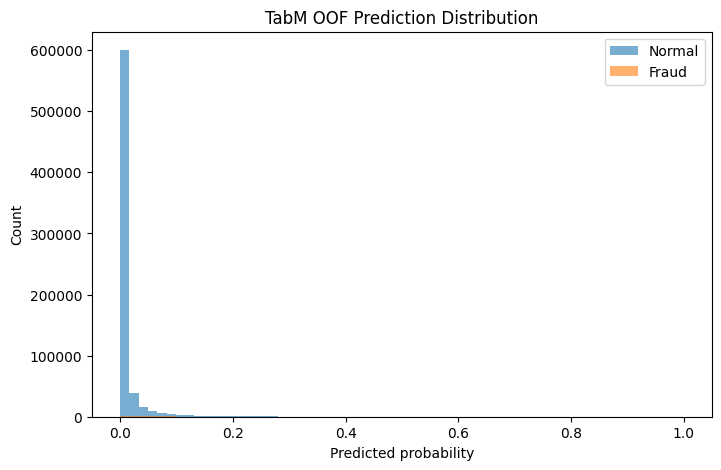

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

y_true = oof_df["is_fraud"].to_numpy()
pred = oof_df["tabm_oof"].to_numpy()

auc = roc_auc_score(y_true, pred)
pr_auc = average_precision_score(y_true, pred)

print("TabM ROC-AUC:", auc)
print("TabM PR-AUC:", pr_auc)
print("Fraud ratio:", y_true.mean())

# Prediction distribution
plt.figure(figsize=(8, 5))

plt.hist(pred[y_true == 0], bins=60, alpha=0.6, label="Normal")
plt.hist(pred[y_true == 1], bins=60, alpha=0.6, label="Fraud")

plt.xlabel("Predicted probability")
plt.ylabel("Count")
plt.title("TabM OOF Prediction Distribution")
plt.legend()
plt.show()

In [ ]:

from google.colab import files
uploaded = files.upload()


Saving kaggle.json to kaggle.json


In [ ]:

import os
import shutil

os.makedirs('/root/.kaggle', exist_ok=True)

shutil.move(
    'kaggle.json',
    '/root/.kaggle/kaggle.json'
)

os.chmod('/root/.kaggle/kaggle.json', 0o600)

print("Kaggle authentication setup complete!")


Kaggle authentication setup complete!


In [ ]:

import kagglehub

playground_path = kagglehub.competition_download(
    'playground-series-s6e11'
)

lm_path = kagglehub.dataset_download(
    'megayak/s6e11-target-first-lm'
)

strike9_path = kagglehub.dataset_download(
    'moranzavdi/s6e11-strike9-lb-095330'
)

strike10_path = kagglehub.dataset_download(
    'amanatar/s6e11-strike10-podium-apex-095340'
)

print("All downloads complete!")


100%|██████████| 29.5M/29.5M [00:02<00:00, 11.9MB/s]

Extracting files...


100%|██████████| 4.39M/4.39M [00:01<00:00, 4.37MB/s]

Extracting files...


100%|██████████| 3.45M/3.45M [00:01<00:00, 3.58MB/s]

Extracting files...


100%|██████████| 8.68M/8.68M [00:01<00:00, 7.56MB/s]

Extracting files...


All downloads complete!


In [ ]:

import os

sources = {
    "LM": lm_path,
    "Strike9": strike9_path,
    "Strike10": strike10_path
}

for name, path in sources.items():
    print(f"\n========== {name} ==========")
    for root, dirs, files in os.walk(path):
        for file in files:
            print(os.path.join(root, file))



========== LM ==========
/root/.cache/kagglehub/datasets/megayak/s6e11-target-first-lm/versions/5/lm_member.py
/root/.cache/kagglehub/datasets/megayak/s6e11-target-first-lm/versions/5/README.md
/root/.cache/kagglehub/datasets/megayak/s6e11-target-first-lm/versions/5/lm_test_fold0.npy
/root/.cache/kagglehub/datasets/megayak/s6e11-target-first-lm/versions/5/lm_oof.npy
/root/.cache/kagglehub/datasets/megayak/s6e11-target-first-lm/versions/5/lm_test.npy

========== Strike9 ==========
/root/.cache/kagglehub/datasets/moranzavdi/s6e11-strike9-lb-095330/versions/2/submission_095330.csv

========== Strike10 ==========
/root/.cache/kagglehub/datasets/amanatar/s6e11-strike10-podium-apex-095340/versions/2/submission_095339.csv
/root/.cache/kagglehub/datasets/amanatar/s6e11-strike10-podium-apex-095340/versions/2/submission_095337.csv
/root/.cache/kagglehub/datasets/amanatar/s6e11-strike10-podium-apex-095340/versions/2/submission_095340.csv
/root/.cache/kagglehub/datasets/amanatar/s6e11-strike10-po

In [ ]:

from google.colab import drive
import os

drive.mount('/content/drive')

tabm_dir = "/content/drive/MyDrive/S6E11_TabM"

for file in os.listdir(tabm_dir):
    print(file)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
tabm_test_predictions.csv
tabm_oof.csv
tabm_fold_results.csv


In [ ]:

import os

sources = {
    "LM": lm_path,
    "Strike 9": strike9_path,
    "Strike 10": strike10_path
}

for name, path in sources.items():
    print(f"\n{'='*20} {name} {'='*20}")
    for root, dirs, files in os.walk(path):
        for file in files:
            full_path = os.path.join(root, file)
            print(full_path)



==================== LM ====================
/root/.cache/kagglehub/datasets/megayak/s6e11-target-first-lm/versions/5/lm_member.py
/root/.cache/kagglehub/datasets/megayak/s6e11-target-first-lm/versions/5/README.md
/root/.cache/kagglehub/datasets/megayak/s6e11-target-first-lm/versions/5/lm_test_fold0.npy
/root/.cache/kagglehub/datasets/megayak/s6e11-target-first-lm/versions/5/lm_oof.npy
/root/.cache/kagglehub/datasets/megayak/s6e11-target-first-lm/versions/5/lm_test.npy

==================== Strike 9 ====================
/root/.cache/kagglehub/datasets/moranzavdi/s6e11-strike9-lb-095330/versions/2/submission_095330.csv

==================== Strike 10 ====================
/root/.cache/kagglehub/datasets/amanatar/s6e11-strike10-podium-apex-095340/versions/2/submission_095339.csv
/root/.cache/kagglehub/datasets/amanatar/s6e11-strike10-podium-apex-095340/versions/2/submission_095337.csv
/root/.cache/kagglehub/datasets/amanatar/s6e11-strike10-podium-apex-095340/versions/2/submission_095340.

## **분석시작**

In [ ]:

import os
import numpy as np
import pandas as pd
from scipy.stats import rankdata, spearmanr, pearsonr

# File paths
strike9_file = os.path.join(
    strike9_path, "submission_095330.csv"
)

strike10_file = os.path.join(
    strike10_path, "submission_095340.csv"
)

lm_test_file = os.path.join(lm_path, "lm_test.npy")

tabm_test_file = (
    "/content/drive/MyDrive/S6E11_TabM/"
    "tabm_test_predictions.csv"
)

# Load predictions
strike9 = pd.read_csv(strike9_file)
strike10 = pd.read_csv(strike10_file)
lm_test = np.load(lm_test_file)
tabm = pd.read_csv(tabm_test_file)

# Rename prediction columns
strike9 = strike9.rename(
    columns={"is_fraud": "strike9"}
)

strike10 = strike10.rename(
    columns={"is_fraud": "strike10"}
)

tabm = tabm.rename(
    columns={"is_fraud": "tabm"}
)

# Merge by ID
pred = (
    strike10[["id", "strike10"]]
    .merge(strike9[["id", "strike9"]], on="id", validate="one_to_one")
    .merge(tabm[["id", "tabm"]], on="id", validate="one_to_one")
)

# Check LM length and align with test IDs
assert len(lm_test) == len(pred), (
    f"LM length: {len(lm_test)}, prediction rows: {len(pred)}"
)

pred["lm"] = lm_test

# Basic validation
print("Merged shape:", pred.shape)
print("Duplicate IDs:", pred["id"].duplicated().sum())
print("Missing values:\n", pred.isnull().sum())
print("\nPrediction summary:")
print(pred[["strike9", "strike10", "lm", "tabm"]].describe())


Merged shape: (299984, 5)
Duplicate IDs: 0
Missing values:
 id          0
strike10    0
strike9     0
tabm        0
lm          0
dtype: int64

Prediction summary:
            strike9      strike10             lm           tabm
count  2.999840e+05  2.999840e+05  299984.000000  299984.000000
mean   1.670000e-02  1.669839e-02       0.500002       0.016895
std    7.461896e-02  7.460828e-02       0.288322       0.070733
min    6.644265e-12  7.145129e-12       0.000007       0.000001
25%    2.479004e-04  2.479019e-04       0.250374       0.000500
50%    1.123996e-03  1.123996e-03       0.500135       0.001782
75%    5.080532e-03  5.080501e-03       0.749580       0.006845
max    9.999948e-01  9.999943e-01       0.999998       0.997751


In [ ]:

# Correlation analysis
cols = ["strike9", "strike10", "lm", "tabm"]

print("Pearson correlation")
print(pred[cols].corr(method="pearson").round(5))

print("\nSpearman correlation")
print(pred[cols].corr(method="spearman").round(5))


Pearson correlation
          strike9  strike10       lm     tabm
strike9   1.00000   0.99942  0.34524  0.93924
strike10  0.99942   1.00000  0.34521  0.93877
lm        0.34524   0.34521  1.00000  0.34956
tabm      0.93924   0.93877  0.34956  1.00000

Spearman correlation
          strike9  strike10       lm     tabm
strike9   1.00000   0.99977  0.97325  0.90987
strike10  0.99977   1.00000  0.97190  0.90776
lm        0.97325   0.97190  1.00000  0.92693
tabm      0.90987   0.90776  0.92693  1.00000


In [ ]:

# Calculate top prediction overlap
def top_overlap(a, b, fraction):
    n = len(a)
    k = int(np.ceil(n * fraction))

    top_a = set(np.argpartition(a, -k)[-k:])
    top_b = set(np.argpartition(b, -k)[-k:])

    intersection = len(top_a & top_b)
    union = len(top_a | top_b)

    return {
        "top_percent": fraction * 100,
        "top_count": k,
        "overlap_count": intersection,
        "overlap_rate": intersection / k,
        "jaccard": intersection / union
    }

pairs = [
    ("Strike10", "TabM", "strike10", "tabm"),
    ("Strike10", "LM", "strike10", "lm"),
    ("Strike9", "TabM", "strike9", "tabm"),
    ("LM", "TabM", "lm", "tabm")
]

results = []

for name_a, name_b, col_a, col_b in pairs:
    for frac in [0.001, 0.005, 0.01]:
        result = top_overlap(
            pred[col_a].to_numpy(),
            pred[col_b].to_numpy(),
            frac
        )
        result["comparison"] = f"{name_a} vs {name_b}"
        results.append(result)

overlap_df = pd.DataFrame(results)

print(overlap_df.round(4).to_string(index=False))


 top_percent  top_count  overlap_count  overlap_rate  jaccard       comparison
         0.1        300            232        0.7733   0.6304 Strike10 vs TabM
         0.5       1500           1181        0.7873   0.6493 Strike10 vs TabM
         1.0       3000           2392        0.7973   0.6630 Strike10 vs TabM
         0.1        300            267        0.8900   0.8018   Strike10 vs LM
         0.5       1500           1349        0.8993   0.8171   Strike10 vs LM
         1.0       3000           2725        0.9083   0.8321   Strike10 vs LM
         0.1        300            234        0.7800   0.6393  Strike9 vs TabM
         0.5       1500           1179        0.7860   0.6474  Strike9 vs TabM
         1.0       3000           2396        0.7987   0.6648  Strike9 vs TabM
         0.1        300            237        0.7900   0.6529       LM vs TabM
         0.5       1500           1196        0.7973   0.6630       LM vs TabM
         1.0       3000           2420        0.8067

In [ ]:
##검증
# Load original competition test data
test = pd.read_csv(
    os.path.join(playground_path, "test.csv")
)

# Check ID alignment
print("Test rows:", len(test))
print("Strike 9 ID order matches:",
      np.array_equal(test["id"], strike9["id"]))

print("Strike 10 ID order matches:",
      np.array_equal(test["id"], strike10["id"]))

print("TabM ID order matches:",
      np.array_equal(test["id"], tabm["id"]))

# Check LM array length
print("LM prediction length:", len(lm_test))
print("Test data length:", len(test))

# Check LM values
print("LM prediction range:",
      np.min(lm_test), np.max(lm_test))


Test rows: 299984
Strike 9 ID order matches: True
Strike 10 ID order matches: True
TabM ID order matches: True
LM prediction length: 299984
Test data length: 299984
LM prediction range: 6.6670223e-06 0.99999833


In [ ]:

import os
import numpy as np
import pandas as pd

from scipy.stats import rankdata
from scipy.special import logit

# Load sample submission
sample = pd.read_csv(
    os.path.join(playground_path, "sample_submission.csv")
)

# Rank-logit transformation
def logit_rank(x):
    n = len(x)
    r = rankdata(x)
    return logit((r - 0.5) / n)

# Transform predictions
A = logit_rank(pred["strike10"].to_numpy())
F = logit_rank(pred["strike9"].to_numpy())
LM = logit_rank(pred["lm"].to_numpy())
T = logit_rank(pred["tabm"].to_numpy())

# Original ensemble
base_score = A + 0.12 * (LM - F)

# Alpha experiments
alphas = [0, 0.05, 0.10, 0.15, 0.20]

# Save directory
save_dir = "/content/drive/MyDrive/S6E11_Ensemble_Experiments"
os.makedirs(save_dir, exist_ok=True)

experiment_results = []

for alpha in alphas:

    # Add TabM correction
    score = base_score + alpha * (T - A)

    # Convert to submission probabilities
    final_pred = (rankdata(score) - 0.5) / len(score)

    # Create submission
    submission = sample.copy()
    submission["is_fraud"] = final_pred

    # Save file
    filename = f"submission_tabm_alpha_{alpha:.2f}.csv"
    filepath = os.path.join(save_dir, filename)

    submission.to_csv(filepath, index=False)

    # Record diagnostics
    experiment_results.append({
        "alpha": alpha,
        "correlation_with_base": np.corrcoef(
            score, base_score
        )[0, 1],
        "score_std": np.std(score),
        "file": filename
    })

# Show results
experiment_df = pd.DataFrame(experiment_results)

print("All experiments saved!")
print(experiment_df.to_string(index=False))

print("\nSaved directory:", save_dir)


All experiments saved!
 alpha  correlation_with_base  score_std                           file
  0.00               1.000000   1.808336 submission_tabm_alpha_0.00.csv
  0.05               0.999789   1.801348 submission_tabm_alpha_0.05.csv
  0.10               0.999149   1.795127 submission_tabm_alpha_0.10.csv
  0.15               0.998072   1.789680 submission_tabm_alpha_0.15.csv
  0.20               0.996552   1.785016 submission_tabm_alpha_0.20.csv

Saved directory: /content/drive/MyDrive/S6E11_Ensemble_Experiments
